Loading datasets...
Original Fake news records: 23481
Original Real news records: 21417

       DUPLICATE CHECK
Duplicate records before removal: 5795
Duplicate records after removal: 0
Records after duplicate removal: 39103

       CLASS DISTRIBUTION
label
Real News    21196
Fake News    17907
Name: count, dtype: int64

       TRAIN TEST SPLIT
Training records: 31282
Testing records: 7821

Train-Test Exact Content Overlap: 0
SUCCESS: No duplicate content between training and testing data.

       TF-IDF VECTORIZATION
Training TF-IDF shape: (31282, 5000)
Testing TF-IDF shape: (7821, 5000)

Training Logistic Regression model...
Training Random Forest model...
Training SVM model...

Generating predictions...

       ROC-AUC SCORES
Logistic Regression: 0.9988
Random Forest:       0.9994
SVM:                 0.9995

       PR-AUC SCORES
Logistic Regression: 0.9989
Random Forest:       0.9994
SVM:                 0.9996


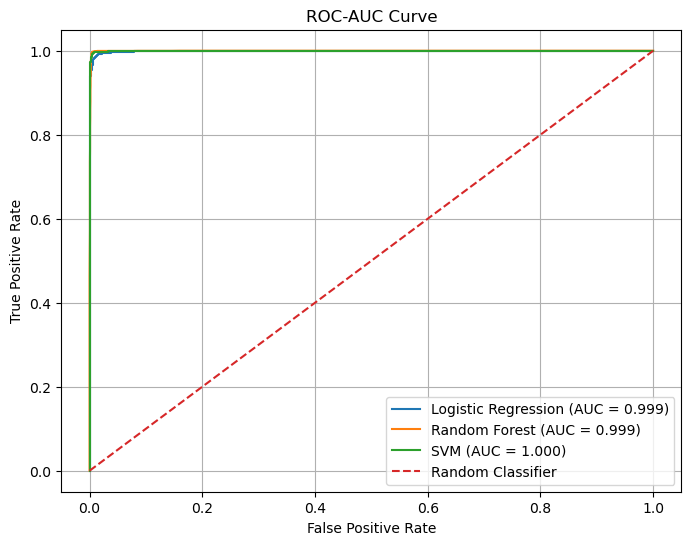

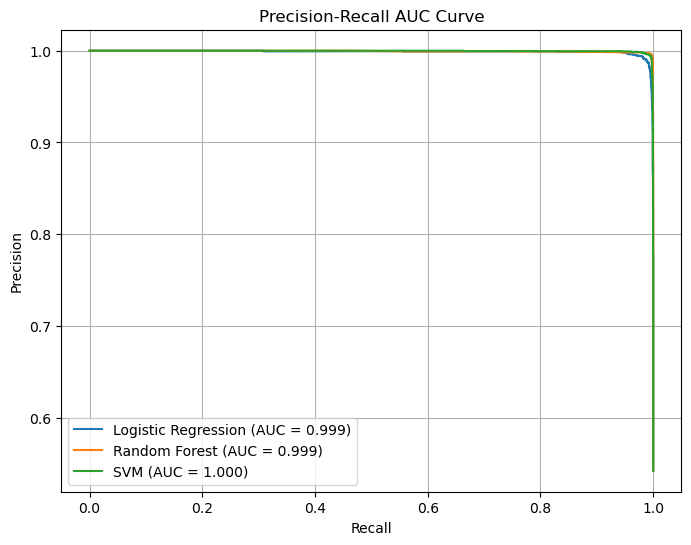


LOGISTIC REGRESSION
Training Accuracy : 99.00%
Testing Accuracy  : 98.76%
Precision         : 98.50%
Recall            : 99.22%
F1-Score          : 98.86%
Train-Test Gap    : 0.24%
Model Status      : GOOD GENERALIZATION

RANDOM FOREST
Training Accuracy : 100.00%
Testing Accuracy  : 99.64%
Precision         : 99.58%
Recall            : 99.76%
F1-Score          : 99.67%
Train-Test Gap    : 0.36%
Model Status      : GOOD GENERALIZATION

SVM
Training Accuracy : 99.90%
Testing Accuracy  : 99.44%
Precision         : 99.32%
Recall            : 99.65%
F1-Score          : 99.48%
Train-Test Gap    : 0.47%
Model Status      : GOOD GENERALIZATION


       FINAL MODEL COMPARISON
              Model  Training Accuracy  Testing Accuracy  Precision   Recall  F1-Score  Train-Test Gap  ROC-AUC   PR-AUC
LOGISTIC REGRESSION           0.989994          0.987597   0.985012 0.992215  0.988600        0.002397 0.998806 0.998876
      RANDOM FOREST           1.000000          0.996420   0.995762 0.997641  0.9

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc
)


# =========================================================
# 1. LOAD DATASETS
# =========================================================

print("Loading datasets...")

fake = pd.read_csv("Fake.csv")
real = pd.read_csv("True.csv")

print("Original Fake news records:", len(fake))
print("Original Real news records:", len(real))


# =========================================================
# 2. ADD LABELS
# =========================================================
# 0 = Fake News
# 1 = Real News

fake["label"] = 0
real["label"] = 1


# =========================================================
# 3. COMBINE DATASETS
# =========================================================

df = pd.concat(
    [fake, real],
    ignore_index=True
)


# =========================================================
# 4. HANDLE MISSING VALUES
# =========================================================

df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")


# =========================================================
# 5. COMBINE TITLE + TEXT
# =========================================================

df["content"] = (
    df["title"].astype(str)
    + " "
    + df["text"].astype(str)
)


# =========================================================
# 6. REMOVE EMPTY ARTICLES
# =========================================================

df["content"] = df["content"].str.strip()

df = df[
    df["content"] != ""
].copy()


# =========================================================
# 7. REMOVE DUPLICATE ARTICLES
# =========================================================
# IMPORTANT:
# Duplicates must be removed BEFORE train-test split.
# This prevents the same article from appearing in both
# training and testing data.


print("\n======================================")
print("       DUPLICATE CHECK")
print("======================================")

duplicates_before = df["content"].duplicated().sum()

print(
    "Duplicate records before removal:",
    duplicates_before
)


# Remove duplicate content
df = df.drop_duplicates(
    subset=["content"]
).reset_index(drop=True)


duplicates_after = df["content"].duplicated().sum()

print(
    "Duplicate records after removal:",
    duplicates_after
)

print(
    "Records after duplicate removal:",
    len(df)
)


# =========================================================
# 8. CHECK CLASS DISTRIBUTION
# =========================================================

print("\n======================================")
print("       CLASS DISTRIBUTION")
print("======================================")

print(
    df["label"]
    .value_counts()
    .rename(
        index={
            0: "Fake News",
            1: "Real News"
        }
    )
)


# =========================================================
# 9. INPUT AND OUTPUT
# =========================================================

X = df["content"]
y = df["label"]


# =========================================================
# 10. TRAIN-TEST SPLIT
# =========================================================
# Split BEFORE TF-IDF.
# Stratify keeps class distribution balanced.


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


print("\n======================================")
print("       TRAIN TEST SPLIT")
print("======================================")

print(
    "Training records:",
    len(X_train)
)

print(
    "Testing records:",
    len(X_test)
)


# =========================================================
# 11. FINAL TRAIN-TEST DUPLICATE CHECK
# =========================================================

train_set = set(X_train)
test_set = set(X_test)

overlap = train_set.intersection(
    test_set
)

print(
    "\nTrain-Test Exact Content Overlap:",
    len(overlap)
)

if len(overlap) == 0:

    print(
        "SUCCESS: No duplicate content "
        "between training and testing data."
    )

else:

    print(
        "WARNING: Data overlap detected!"
    )


# =========================================================
# 12. TF-IDF VECTORIZATION
# =========================================================
# IMPORTANT:
#
# fit_transform() ONLY on training data.
#
# transform() on testing data.
#
# This prevents TF-IDF data leakage.


print("\n======================================")
print("       TF-IDF VECTORIZATION")
print("======================================")

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)


X_train_tfidf = vectorizer.fit_transform(
    X_train
)


X_test_tfidf = vectorizer.transform(
    X_test
)


print(
    "Training TF-IDF shape:",
    X_train_tfidf.shape
)

print(
    "Testing TF-IDF shape:",
    X_test_tfidf.shape
)


# =========================================================
# 13. TRAIN LOGISTIC REGRESSION
# =========================================================

print("\nTraining Logistic Regression model...")

logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_tfidf,
    y_train
)


# =========================================================
# 14. TRAIN RANDOM FOREST
# =========================================================

print("Training Random Forest model...")

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_tfidf,
    y_train
)


# =========================================================
# 15. TRAIN SVM
# =========================================================

print("Training SVM model...")

svm_model = LinearSVC(
    random_state=42,
    max_iter=5000
)

svm_model.fit(
    X_train_tfidf,
    y_train
)


# =========================================================
# 16. PREDICTIONS
# =========================================================

print("\nGenerating predictions...")


# Logistic Regression
logistic_train_pred = (
    logistic_model.predict(
        X_train_tfidf
    )
)

logistic_test_pred = (
    logistic_model.predict(
        X_test_tfidf
    )
)


# Random Forest
rf_train_pred = (
    random_forest_model.predict(
        X_train_tfidf
    )
)

rf_test_pred = (
    random_forest_model.predict(
        X_test_tfidf
    )
)


# SVM
svm_train_pred = (
    svm_model.predict(
        X_train_tfidf
    )
)

svm_test_pred = (
    svm_model.predict(
        X_test_tfidf
    )
)


# =========================================================
# 17. PROBABILITY / DECISION SCORES
# =========================================================

# Logistic Regression
logistic_prob = (
    logistic_model
    .predict_proba(
        X_test_tfidf
    )[:, 1]
)


# Random Forest
rf_prob = (
    random_forest_model
    .predict_proba(
        X_test_tfidf
    )[:, 1]
)


# SVM
# LinearSVC does not provide predict_proba().
# Therefore decision_function() is used.

svm_scores = (
    svm_model
    .decision_function(
        X_test_tfidf
    )
)


# =========================================================
# 18. ROC-AUC
# =========================================================

logistic_roc_auc = roc_auc_score(
    y_test,
    logistic_prob
)

rf_roc_auc = roc_auc_score(
    y_test,
    rf_prob
)

svm_roc_auc = roc_auc_score(
    y_test,
    svm_scores
)


print("\n======================================")
print("       ROC-AUC SCORES")
print("======================================")

print(
    f"Logistic Regression: "
    f"{logistic_roc_auc:.4f}"
)

print(
    f"Random Forest:       "
    f"{rf_roc_auc:.4f}"
)

print(
    f"SVM:                 "
    f"{svm_roc_auc:.4f}"
)


# =========================================================
# 19. PRECISION-RECALL AUC
# =========================================================


precision_lr, recall_lr, _ = (
    precision_recall_curve(
        y_test,
        logistic_prob
    )
)

lr_pr_auc = auc(
    recall_lr,
    precision_lr
)


precision_rf, recall_rf, _ = (
    precision_recall_curve(
        y_test,
        rf_prob
    )
)

rf_pr_auc = auc(
    recall_rf,
    precision_rf
)


precision_svm, recall_svm, _ = (
    precision_recall_curve(
        y_test,
        svm_scores
    )
)

svm_pr_auc = auc(
    recall_svm,
    precision_svm
)


print("\n======================================")
print("       PR-AUC SCORES")
print("======================================")

print(
    f"Logistic Regression: "
    f"{lr_pr_auc:.4f}"
)

print(
    f"Random Forest:       "
    f"{rf_pr_auc:.4f}"
)

print(
    f"SVM:                 "
    f"{svm_pr_auc:.4f}"
)


# =========================================================
# 20. ROC CURVE
# =========================================================

fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    logistic_prob
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    rf_prob
)

fpr_svm, tpr_svm, _ = roc_curve(
    y_test,
    svm_scores
)


plt.figure(
    figsize=(8, 6)
)


plt.plot(
    fpr_lr,
    tpr_lr,
    label=(
        f"Logistic Regression "
        f"(AUC = {logistic_roc_auc:.3f})"
    )
)


plt.plot(
    fpr_rf,
    tpr_rf,
    label=(
        f"Random Forest "
        f"(AUC = {rf_roc_auc:.3f})"
    )
)


plt.plot(
    fpr_svm,
    tpr_svm,
    label=(
        f"SVM "
        f"(AUC = {svm_roc_auc:.3f})"
    )
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC-AUC Curve"
)

plt.legend()

plt.grid()

plt.show()


# =========================================================
# 21. PRECISION-RECALL CURVE
# =========================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(
    recall_lr,
    precision_lr,
    label=(
        f"Logistic Regression "
        f"(AUC = {lr_pr_auc:.3f})"
    )
)


plt.plot(
    recall_rf,
    precision_rf,
    label=(
        f"Random Forest "
        f"(AUC = {rf_pr_auc:.3f})"
    )
)


plt.plot(
    recall_svm,
    precision_svm,
    label=(
        f"SVM "
        f"(AUC = {svm_pr_auc:.3f})"
    )
)


plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Precision-Recall AUC Curve"
)

plt.legend()

plt.grid()

plt.show()


# =========================================================
# 22. MODEL EVALUATION FUNCTION
# =========================================================


def evaluate_model(
    model_name,
    train_predictions,
    test_predictions
):

    train_accuracy = accuracy_score(
        y_train,
        train_predictions
    )

    test_accuracy = accuracy_score(
        y_test,
        test_predictions
    )

    precision = precision_score(
        y_test,
        test_predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        test_predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        test_predictions,
        zero_division=0
    )

    train_test_gap = (
        train_accuracy -
        test_accuracy
    )


    print("\n======================================")
    print(model_name)
    print("======================================")

    print(
        f"Training Accuracy : "
        f"{train_accuracy * 100:.2f}%"
    )

    print(
        f"Testing Accuracy  : "
        f"{test_accuracy * 100:.2f}%"
    )

    print(
        f"Precision         : "
        f"{precision * 100:.2f}%"
    )

    print(
        f"Recall            : "
        f"{recall * 100:.2f}%"
    )

    print(
        f"F1-Score          : "
        f"{f1 * 100:.2f}%"
    )

    print(
        f"Train-Test Gap    : "
        f"{train_test_gap * 100:.2f}%"
    )


    # =====================================================
    # OVERFITTING CHECK
    # =====================================================

    if train_test_gap > 0.10:

        status = "POSSIBLE OVERFITTING"

    # =====================================================
    # UNDERFITTING CHECK
    # =====================================================

    elif (
        train_accuracy < 0.70
        and
        test_accuracy < 0.70
    ):

        status = "POSSIBLE UNDERFITTING"

    else:

        status = "GOOD GENERALIZATION"


    print(
        "Model Status      :",
        status
    )


    return {
        "Model": model_name,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Train-Test Gap": train_test_gap
    }


# =========================================================
# 23. EVALUATE MODELS
# =========================================================

logistic_results = evaluate_model(
    "LOGISTIC REGRESSION",
    logistic_train_pred,
    logistic_test_pred
)


rf_results = evaluate_model(
    "RANDOM FOREST",
    rf_train_pred,
    rf_test_pred
)


svm_results = evaluate_model(
    "SVM",
    svm_train_pred,
    svm_test_pred
)


# =========================================================
# 24. MODEL COMPARISON
# =========================================================

comparison = pd.DataFrame(
    [
        logistic_results,
        rf_results,
        svm_results
    ]
)


comparison["ROC-AUC"] = [
    logistic_roc_auc,
    rf_roc_auc,
    svm_roc_auc
]


comparison["PR-AUC"] = [
    lr_pr_auc,
    rf_pr_auc,
    svm_pr_auc
]


print("\n\n======================================")
print("       FINAL MODEL COMPARISON")
print("======================================")

print(
    comparison.to_string(
        index=False
    )
)


# =========================================================
# 25. CLASSIFICATION REPORTS
# =========================================================

print("\n======================================")
print("       LOGISTIC REGRESSION REPORT")
print("======================================")

print(
    classification_report(
        y_test,
        logistic_test_pred,
        target_names=[
            "Fake News",
            "Real News"
        ]
    )
)


print("\n======================================")
print("       RANDOM FOREST REPORT")
print("======================================")

print(
    classification_report(
        y_test,
        rf_test_pred,
        target_names=[
            "Fake News",
            "Real News"
        ]
    )
)


print("\n======================================")
print("       SVM REPORT")
print("======================================")

print(
    classification_report(
        y_test,
        svm_test_pred,
        target_names=[
            "Fake News",
            "Real News"
        ]
    )
)


# =========================================================
# 26. CONFUSION MATRICES
# =========================================================

print("\n======================================")
print("       CONFUSION MATRICES")
print("======================================")


print("\nLogistic Regression:")
print(
    confusion_matrix(
        y_test,
        logistic_test_pred
    )
)


print("\nRandom Forest:")
print(
    confusion_matrix(
        y_test,
        rf_test_pred
    )
)


print("\nSVM:")
print(
    confusion_matrix(
        y_test,
        svm_test_pred
    )
)


# =========================================================
# 27. BEST MODEL - F1 SCORE
# =========================================================

best_f1_model = comparison.loc[
    comparison["F1-Score"].idxmax()
]


print("\n======================================")
print("       BEST MODEL - F1 SCORE")
print("======================================")

print(
    "Model:",
    best_f1_model["Model"]
)

print(
    f"F1-Score: "
    f"{best_f1_model['F1-Score'] * 100:.2f}%"
)


# =========================================================
# 28. BEST MODEL - ROC-AUC
# =========================================================

best_roc_model = comparison.loc[
    comparison["ROC-AUC"].idxmax()
]


print("\n======================================")
print("       BEST MODEL - ROC-AUC")
print("======================================")

print(
    "Model:",
    best_roc_model["Model"]
)

print(
    f"ROC-AUC: "
    f"{best_roc_model['ROC-AUC']:.4f}"
)


# =========================================================
# 29. BEST MODEL - PR-AUC
# =========================================================

best_pr_model = comparison.loc[
    comparison["PR-AUC"].idxmax()
]


print("\n======================================")
print("       BEST MODEL - PR-AUC")
print("======================================")

print(
    "Model:",
    best_pr_model["Model"]
)

print(
    f"PR-AUC: "
    f"{best_pr_model['PR-AUC']:.4f}"
)


# =========================================================
# 30. FINAL DATA LEAKAGE CONFIRMATION
# =========================================================

print("\n======================================")
print("       FINAL DATA LEAKAGE CHECK")
print("======================================")

print(
    "Duplicate records remaining:",
    df["content"].duplicated().sum()
)

print(
    "Train-Test exact overlap:",
    len(overlap)
)


if (
    df["content"].duplicated().sum() == 0
    and
    len(overlap) == 0
):

    print(
        "RESULT: No exact duplicate "
        "data leakage detected."
    )

else:

    print(
        "RESULT: Possible data leakage detected."
    )


# =========================================================
# 31. TEST YOUR OWN NEWS
# =========================================================

print("\n======================================")
print("       FAKE NEWS DETECTOR")
print("======================================")

while True:

    news = input(
        "\nEnter a news article "
        "(or type 'exit' to stop):\n"
    )


    if news.lower() == "exit":

        print("\nProgram ended.")

        break


    if news.strip() == "":

        print(
            "Please enter some news text."
        )

        continue


    # Convert entered news into TF-IDF
    news_vector = vectorizer.transform(
        [news]
    )


    # =====================================================
    # LOGISTIC REGRESSION PREDICTION
    # =====================================================

    prediction = (
        logistic_model.predict(
            news_vector
        )[0]
    )


    probability = (
        logistic_model
        .predict_proba(
            news_vector
        )[0]
    )


    if prediction == 0:

        confidence = (
            probability[0] * 100
        )

        print(
            "\n--------------------------------------"
        )

        print(
            "Prediction: FAKE NEWS"
        )

        print(
            f"Confidence: "
            f"{confidence:.2f}%"
        )

        print(
            "--------------------------------------"
        )

    else:

        confidence = (
            probability[1] * 100
        )

        print(
            "\n--------------------------------------"
        )

        print(
            "Prediction: REAL NEWS"
        )

        print(
            f"Confidence: "
            f"{confidence:.2f}%"
        )

        print(
            "--------------------------------------"
        )